In [10]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/9/2022
# version ='1.0'

### Demo: An Experiment on Convergence Rate on A Family of Self-Concordant Function

In the text book {book-convex-2004}, section 9.6, 'Self-Concordant', the analysis of Newton's method for self-concordant functions was discussed.  The bound on the number of Newton iterations is,

$$
\dfrac{20-8\alpha}{\alpha\beta(1-2\alpha)^2}(f(x^{(0)})-p^*)+\log_2\log_2(1/\epsilon)
$$

With tolerance $\epsilon=1e-10$, $\alpha=0.1, \beta=0.8$, the bound is

\begin{equation}
375(f(x^{(0)})-p^*) + 6
\label{eq:bound}
\end{equation}


In the textbook, an experiment was designed to compare the above upper bound to the actual number of iterations to minimize a family of self-concordant functions.

$$
f(x) =-\displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}
$$

In this demo, the experiment is repeated to further visualize the conclusions.

In the experiment, the coefficients of $A$ are generated from independent normal distributions with
mean zero and unit variance. To make the minimization problem always feasible, the generation of $b$ follows $b = \xi + Ax'$, 
where, $\xi\in(0,1)^m$, $x'\in(-1, 1)^n$, i.e. $x'\in \mathcal{D}_f$. Nevertheless, the minimization problem may not be low bounded. Those unbounded problems with the pair of $(A, b)$ will be discarded.

In the Newton's method, the starting point are taken as $x^{(0)}=x^*+sv$, where $v\in(0,1)^n$ and $||v||_2=1$. $s\in (0, S)$ randomly, where $S=\max\{s|x^*+sv \in \mathcal{D}_f\}$.

In the experiment, total $N$ pair of $(A, b)$ are generated randomly, each as an instance of problem. In each problem, $K$ of randomly $s$ values are selected as different starting point for the Newton's method. 

The first experiment result clearly shows that the bound from the Eq.[\ref{eq:bound}] is too conservative.


More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).

In [11]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

In [12]:
def my_f_feasible(x, A, b):
    return np.all(b - A @ x > 0)


def my_f(x, A, b):
    return - np.sum(np.log(b - A @ x)).item()


def my_gradient_f(x, A, b):
    return A.T @ (1 / (b - A @ x))


def my_hessian_f(x, A, b):
    diag = np.diag(np.squeeze(1 / ((b - A @ x) ** 2)))
    hessian = A.T @ diag @ A
    return hessian

In [13]:
def get_max_bound(x0, v, A, b):
    m = A.shape[0]
    nominator = b - A @ x0
    if not np.all(nominator > 0):
        raise RuntimeError('b-Ax0 should be larger than zeros')

    s = (b - A @ x0) / (A @ v)
    infs = np.inf * np.ones((m, 1))
    s_clipped = np.where(s > 0, s, infs)
    return np.min(s_clipped)

In [14]:
def my_newton_step_decrement(x, args):
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

In [15]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    t = 1
    while (not my_f_feasible(x + delta_x * t, *args)) \
            or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
        t = beta * t
    return t

In [16]:
def generate_an_experiment(n_, m_, seed_, alpha_, beta_):
    n = n_
    m = m_
    alpha = alpha_
    beta = beta_
    np.random.seed(seed_)
    converged = False
    A = None
    b = None
    x0 = None
    x_p = None

    converged_trial = 0
    while not converged:
        #print('Info: [{}] convergence trial.'.format(converged_trial))
        converged_trial = converged_trial + 1
        converged = True

        mu, sigma = 0, 1
        A = np.random.normal(mu, sigma, (m, n))

        u = 10
        x0 = np.random.rand(n, 1) * (2 * u) - u
        b0 = A @ x0

        b_noise_scale = 100
        b = b0 + np.random.rand(m, 1) * b_noise_scale

        args = (A, b)
        epsilon_decrement = 1e-15
        epsilon_f = 1e-12

        x = x0
        x_nt, decrement = my_newton_step_decrement(x, args)
        iteration = 0
        f_last = my_f(x, *args)
        f_current = my_f(x, *args)
        while decrement / 2 > epsilon_decrement or math.fabs(f_current - f_last) > epsilon_f:
            t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
            x_next = x + t * x_nt
            x = x_next
            x_nt, decrement = my_newton_step_decrement(x, args)
            f_last, f_current = f_current, my_f(x, *args)
            iteration = iteration + 1
            if iteration > 100:
                converged = False
                break
        x_p = x
    return converged, A, b, x_p, x0

In [17]:
def plot_self_concordant_convergence_statistics(ns, ms, num_epoch):
    indices = [i+1 for i in range(len(ns))]
    plt.figure(figsize=(12, 4))
    for n, m, index in zip(ns, ms, indices):
        ax = plt.subplot(1, len(indices), index)
        seeds = np.arange(0, num_epoch)
        alpha = 0.1
        beta = 0.8
        marker = '+'

        for seed_i in range(len(seeds)):
            seed = seeds[seed_i]
            converged, A, b, x_p, x0 = generate_an_experiment(n, m, seed, alpha, beta)
            if not converged:
                raise RuntimeError("It should return a converged experiment.")

            f0_fmin = []
            num_iters = []

            args = (A, b)
            f_min = my_f(x_p, *args)
            #print('Info: [{}] f_min={}'.format(seed_i, f_min))
            epsilon = 1e-10

            v = np.random.rand(n, 1) * 2 - 1 # random in (-1, 1)
            v = v / np.linalg.norm(v)
            s = get_max_bound(x_p, v, *args)

            n_s = 50
            s_i = 0

            while s_i < n_s:
                if np.isinf(s):
                    s0 = np.random.random(1) * 100.
                else:
                    s0 = np.random.random(1) * s
                x0 = x_p + s0 * v
                f0 = my_f(x0, *args)
                if math.fabs(f0 - f_min) > 35:
                    continue
                else:
                    s_i = s_i + 1

                fx = []
                tx = []
                decrements = []
                x = x0
                x_nt, decrement = my_newton_step_decrement(x, args)
                fx.append(f0)
                decrements.append(decrement)
                iteration = 0

                while math.fabs(fx[-1] - f_min) > epsilon:
                    t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
                    tx.append(t)
                    x_next = x + t * x_nt
                    x = x_next
                    x_nt, decrement = my_newton_step_decrement(x, args)

                    fx.append(my_f(x, *args))
                    decrements.append(decrement)
                    iteration = iteration + 1
                #print('Info: [{}][{}][{}] decrement={}, fx={}'.format(seed_i, s_i, iteration, decrement, fx[-1]))
                f0_fmin.append(fx[0] - f_min)
                num_iters.append(len(fx))

            ax.plot(f0_fmin, num_iters, marker=marker, fillstyle='none', linestyle='none', color='C{}'.format(seed_i))
        ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
        ax.grid()
        ax.set_xlim(0, 30)
        ax.set_ylim(0, 20)
        ax.set_xlabel(r'$f(x)-p^*$')
        ax.set_ylabel('iterations')
        ax.set_title('Newton iterations when n={}, m={}'.format(n, m))
    plt.show()

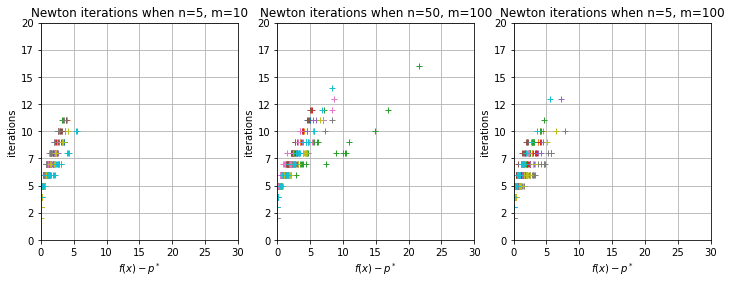

In [18]:
if __name__ == "__main__":
    ns = [5, 50, 5]
    ms = [10, 100, 100]
    plot_self_concordant_convergence_statistics(ns=ns, ms=ms, num_epoch=10)